# Ventanas frías para la elaboración de chuño en Huancané

Grupo 9 · Inteligencia Artificial 1INF24 · Horario 0782

Estimamos la probabilidad de que las tres mínimas siguientes sean de −3 °C o menos. La evaluación usa las temporadas de abril a septiembre de 2016 a 2020.

## 1. Datos

El CSV contiene la serie diaria de la celda de Huancané (−15,225°, −69,755°), extraída de PISCOt v1.2 a 0,10°. Las columnas son `fecha`, `tmin` y `tmax`, con temperaturas en °C.

La ruta predeterminada apunta al CSV de la entrega. En Colab, la celda de lectura abre el selector de archivos cuando hace falta.

In [1]:
from __future__ import annotations
import hashlib
import inspect
import json
import platform
import pprint
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

get_ipython().run_line_magic("matplotlib", "inline")


In [2]:
RUTA_CSV = Path("PISCOt_Huancane_1981_2020.csv")
OUT = Path("resultados_grupo9")
OUT.mkdir(exist_ok=True)

if not RUTA_CSV.is_file():
    try:
        from google.colab import files as archivos_colab
    except ImportError:
        raise FileNotFoundError(
            f"Falta {RUTA_CSV.name}. Ubique el CSV junto al notebook o indique su ruta en RUTA_CSV."
        ) from None

    archivos = archivos_colab.upload()
    candidatos = [Path(nombre) for nombre in archivos if Path(nombre).suffix.lower() == ".csv"]
    if len(candidatos) != 1:
        raise ValueError("Cargue el único CSV incluido en la entrega.")
    RUTA_CSV = candidatos[0]

print(f"Python {platform.python_version()} · NumPy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__}")


Python 3.12.14 · NumPy 2.5.4 · pandas 3.1.1 · scikit-learn 1.9.1


In [3]:
SEED = 2026

THERMALS = [-3.0, -2.0, -4.0]

MODELS = ["logistica", "arbol", "knn", "mezcla", "frecuencia_mensual", "persistencia"]

CLASSIFIERS = MODELS[:4]

FEATURES = [f"{v}_lag_{lag}" for v in ["tmin", "tmax"] for lag in range(6, -1, -1)] + [
    "sin_dia",
    "cos_dia",
]

FOLDS = [(1981, 1995, 1996, 2000), (1981, 2000, 2001, 2005), (1981, 2005, 2006, 2010)]

GRIDS = {
    "logistica": [{"C": c} for c in [0.1, 1.0, 10.0]],
    "arbol": [
        {"max_depth": d, "min_samples_leaf": leaf}
        for d in [3, 5, 8]
        for leaf in [30, 10]
    ],
    "knn": [{"n_neighbors": k} for k in [31, 15, 5]],
}

FUNCIONES_CODIGO = [
    "clean_json",
    "write_json",
    "sha",
    "save_csv",
    "leer_serie",
    "make_examples",
    "score",
    "choose_threshold",
    "model_factory",
    "select_config",
    "select_principal",
    "episodes",
    "sanity_tests",
    "prepare",
    "bootstrap_test",
    "intervals",
    "test",
    "describir_preprocesamiento",
    "auditar_escaladores",
    "codigo_fuente_ejecutado",
    "huella_codigo",
    "resumir",
]


In [4]:
def clean_json(obj):
    if isinstance(obj, dict):
        return {str(k): clean_json(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [clean_json(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return clean_json(obj.tolist())
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, (np.floating, float)):
        return float(obj) if np.isfinite(obj) else None
    return obj


def write_json(path, obj):
    Path(path).write_text(
        json.dumps(
            clean_json(obj),
            ensure_ascii=False,
            indent=2,
            sort_keys=True,
            allow_nan=False,
        ),
        encoding="utf-8",
    )


def sha(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()


def save_csv(df, path):
    df.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.12g",
        date_format="%Y-%m-%d",
    )


def codigo_fuente_ejecutado():
    """Exporta funciones visibles y parámetros; también funciona en celdas Jupyter."""
    cabecera = """from __future__ import annotations
import hashlib
import inspect
import json
import platform
import pprint
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
"""
    parametros = "\n".join(
        nombre + " = " + pprint.pformat(globals()[nombre], width=88, sort_dicts=False)
        for nombre in [
            "SEED",
            "THERMALS",
            "MODELS",
            "CLASSIFIERS",
            "FEATURES",
            "FOLDS",
            "GRIDS",
            "FUNCIONES_CODIGO",
        ]
    )
    funciones = "\n\n".join(
        inspect.getsource(globals()[nombre]).strip() for nombre in FUNCIONES_CODIGO
    )
    return cabecera + "\n" + parametros + "\n\n" + funciones + "\n"


def huella_codigo():
    return hashlib.sha256(codigo_fuente_ejecutado().encode("utf-8")).hexdigest()


In [5]:
def leer_serie(ruta):
    serie = pd.read_csv(ruta, dtype="string")
    if set(serie.columns) != {"fecha", "tmin", "tmax"}:
        raise ValueError("El CSV debe tener las columnas fecha, tmin y tmax.")

    fechas = pd.to_datetime(serie["fecha"], format="%Y-%m-%d", errors="raise")
    calendario = pd.date_range("1981-01-01", "2020-12-31", freq="D", name="fecha")
    if not np.array_equal(fechas.to_numpy(dtype="datetime64[D]"), calendario.to_numpy(dtype="datetime64[D]")):
        raise ValueError("La serie debe incluir una fila por día, en orden, entre 1981 y 2020.")

    diaria = serie[["tmin", "tmax"]].astype("float64").set_axis(calendario)
    tmin_finita = np.isfinite(diaria.tmin)
    tmax_finita = np.isfinite(diaria.tmax)
    orden_temperaturas = diaria.tmin <= diaria.tmax
    diaria["valido_dia"] = tmin_finita & tmax_finita & orden_temperaturas

    auditoria = {
        "filas": len(diaria),
        "primera_fecha": str(calendario[0].date()),
        "ultima_fecha": str(calendario[-1].date()),
        "tmin_no_finita": int((~tmin_finita).sum()),
        "tmax_no_finita": int((~tmax_finita).sum()),
        "tmin_supera_tmax": int((tmin_finita & tmax_finita & ~orden_temperaturas).sum()),
        "dias_invalidos": int((~diaria.valido_dia).sum()),
    }
    return diaria, auditoria


daily, audit = leer_serie(RUTA_CSV)
manifest = {
    "archivo_csv": RUTA_CSV.name,
    "sha256_csv": sha(RUTA_CSV),
    "producto": "PISCOt v1.2 010",
    "doi": "10.6084/m9.figshare.22712365.v3",
    "latitud": -15.225,
    "longitud": -69.755,
    "temperaturas": "°C",
}
write_json(OUT / "manifest_fuentes.json", manifest)
write_json(OUT / "auditoria_datos.json", audit)
display(pd.DataFrame([audit]))
display(daily.head())


,filas,primera_fecha,ultima_fecha,tmin_no_finita,tmax_no_finita,tmin_supera_tmax,dias_invalidos
0,14610,1981-01-01,2020-12-31,0,0,0,0


,tmin,tmax,valido_dia
fecha,,,
1981-01-01,4.72,16.879999,True
1981-01-02,3.50,15.040000,True
1981-01-03,4.22,15.080000,True
1981-01-04,3.58,15.280000,True
1981-01-05,4.18,13.540000,True


## 2. Diagnóstico en entrenamiento

Revisamos la distribución de las temperaturas por mes en 1981–2010. El rango intercuartílico describe los extremos. Las observaciones válidas se conservan.

In [6]:
def describir_preprocesamiento(daily, out):
    """Descripción del entrenamiento; los diagnósticos no alteran observaciones."""
    train = daily.loc["1981-01-01":"2010-12-31"].copy()
    train.loc[~train.valido_dia, ["tmin", "tmax"]] = np.nan
    resumen = (
        train[["tmin", "tmax"]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
    )
    save_csv(
        resumen.reset_index(names="variable"),
        out / "resumen_temperaturas_entrenamiento.csv",
    )
    rows = []
    # Las colas se describen dentro de cada mes para no confundir estación con anomalía.
    for month, g in train.groupby(train.index.month):
        for variable in ["tmin", "tmax"]:
            q1, q3 = g[variable].quantile([0.25, 0.75])
            iqr = q3 - q1
            lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            fuera = (g[variable] < lo) | (g[variable] > hi)
            rows.append(
                {
                    "month": month,
                    "variable": variable,
                    "n_validos": int(g[variable].notna().sum()),
                    "IQR_inferior": lo,
                    "IQR_superior": hi,
                    "n_fuera_IQR": int(fuera.sum()),
                    "accion": "Conservar: indicador exploratorio, no error demostrado",
                }
            )
    save_csv(pd.DataFrame(rows), out / "diagnostico_extremos_entrenamiento.csv")
    write_json(
        out / "decisiones_preprocesamiento.json",
        {
            "periodo_diagnostico": "1981-2010",
            "control": [
                "dimensiones",
                "unidad Celsius",
                "malla 0.10",
                "fechas",
                "duplicados",
                "calendario completo",
                "finitud",
                "Tmin <= Tmax",
            ],
            "dias_invalidos": int((~daily.valido_dia).sum()),
            "limpieza": "Día inválido invalida cualquier ventana que lo use en historia u objetivo; no se rellena la etiqueta.",
            "imputacion": "Ninguna: se excluyen ventanas inválidas. En estos originales no se requieren exclusiones.",
            "extremos": "Se conservan; las heladas son el fenómeno objetivo. IQR mensual solo describe, no elimina ni recorta.",
            "escalado": "StandardScaler dentro del pipeline de logística y KNN, aprendido solo en entrenamiento de cada pliegue; árbol sin escalado.",
            "clases": "Frecuencia original, sin SMOTE ni pesos diferenciados; umbrales elegidos en validación.",
            "dimensionalidad": "16 atributos predefinidos; no se aplica PCA ni selección posterior basada en prueba.",
            "metadata_min_max": "No se usan para recortar: no describen todos los extremos de esta celda.",
        },
    )
    return resumen


In [7]:
resumen = describir_preprocesamiento(daily, OUT)
display(resumen)
display(pd.read_csv(OUT / "diagnostico_extremos_entrenamiento.csv"))


,count,mean,std,min,1%,25%,50%,75%,99%,max
tmin,10957.0,0.100991,4.186042,-13.78,-9.2700,-3.41,1.25,3.660000,5.9600,6.880000
tmax,10957.0,15.692704,1.645958,6.95,11.9656,14.57,15.65,16.790001,19.4344,21.709999


,month,variable,n_validos,IQR_inferior,IQR_superior,n_fuera_IQR,accion
0,1,tmin,930,2.115000,7.114999,25,"Conservar: indicador exploratorio, no error de..."
1,1,tmax,930,11.032500,19.632500,2,"Conservar: indicador exploratorio, no error de..."
2,2,tmin,847,1.820000,7.140000,19,"Conservar: indicador exploratorio, no error de..."
3,2,tmax,847,11.072500,19.892500,2,"Conservar: indicador exploratorio, no error de..."
4,3,tmin,930,0.580000,7.380000,21,"Conservar: indicador exploratorio, no error de..."
5,3,tmax,930,11.730000,19.150002,8,"Conservar: indicador exploratorio, no error de..."
6,4,tmin,900,-3.757500,6.362500,10,"Conservar: indicador exploratorio, no error de..."
7,4,tmax,900,12.381250,19.231250,11,"Conservar: indicador exploratorio, no error de..."
8,5,tmin,930,-10.402500,4.417500,0,"Conservar: indicador exploratorio, no error de..."
9,5,tmax,930,12.680000,18.520000,14,"Conservar: indicador exploratorio, no error de..."


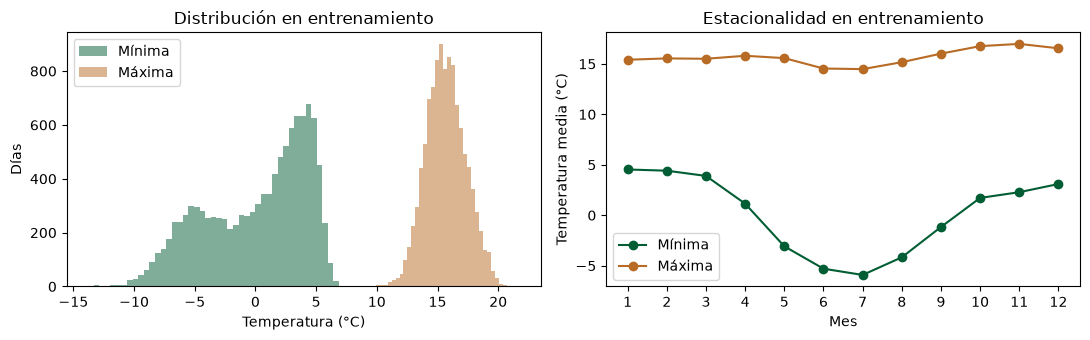

In [8]:
entrenamiento_diario = daily.loc["1981-01-01":"2010-12-31"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for variable, color in [("tmin", "#015D34"), ("tmax", "#B86B24")]:
    leyenda = {"tmin": "Mínima", "tmax": "Máxima"}[variable]
    valores = entrenamiento_diario.loc[entrenamiento_diario.valido_dia, variable]
    ax[0].hist(valores, bins=45, alpha=0.5, label=leyenda, color=color)
    medias = valores.groupby(valores.index.month).mean()
    ax[1].plot(medias.index, medias.values, marker="o", label=leyenda, color=color)
ax[0].set(
    xlabel="Temperatura (°C)", ylabel="Días", title="Distribución en entrenamiento"
)
ax[1].set(
    xlabel="Mes",
    ylabel="Temperatura media (°C)",
    title="Estacionalidad en entrenamiento",
    xticks=range(1, 13),
)
for a in ax:
    a.legend()
fig.tight_layout()
fig.savefig(OUT / "diagnostico_temperaturas_entrenamiento.png", dpi=160)
plt.show()


## 3. Atributos y etiqueta

Cada emisión usa siete mínimas y siete máximas hasta el día `t`, más el seno y el coseno del día del año. La etiqueta vale 1 si las mínimas de `t+1` a `t+3` cumplen el umbral térmico. Se excluyen las ventanas con días inválidos en sus atributos o en su etiqueta.

El ajuste usa 1981–2010 y la validación usa 2011–2015. Los últimos cinco años se reservan para la prueba.

In [9]:
def make_examples(daily, thermal, min_year=1981, max_year=2020):
    """t-6..t son atributos; t+1..t+3 son objetivo. QC en diez dias."""
    x = pd.DataFrame(index=daily.index)
    for v in ["tmin", "tmax"]:
        for lag in range(6, -1, -1):
            x[f"{v}_lag_{lag}"] = daily[v].shift(lag)
    denominator = np.where(daily.index.is_leap_year, 366.0, 365.0)
    angle = 2 * np.pi * daily.index.day_of_year.to_numpy() / denominator
    x["sin_dia"], x["cos_dia"] = np.sin(angle), np.cos(angle)
    history_valid = (
        pd.concat([daily.valido_dia.shift(k) for k in range(7)], axis=1)
        .eq(True)
        .all(axis=1)
    )
    target_valid = (
        pd.concat([daily.valido_dia.shift(-k) for k in range(1, 4)], axis=1)
        .eq(True)
        .all(axis=1)
    )
    future = pd.concat([daily.tmin.shift(-k) for k in range(1, 4)], axis=1)
    past3 = pd.concat([daily.tmin.shift(k) for k in range(3)], axis=1)
    x["valido_historia"], x["valido_objetivo"] = history_valid, target_valid
    x["valido"] = history_valid & target_valid
    x["y"] = future.le(thermal).all(axis=1).astype(float).where(x.valido)
    x["persistencia"] = past3.le(thermal).all(axis=1).astype(float).where(x.valido)
    x["objetivo_inicio"] = x.index + pd.Timedelta(days=1)
    x["objetivo_fin"] = x.index + pd.Timedelta(days=3)
    x["year"], x["month"] = x.index.year, x.index.month
    mmdd = x.index.strftime("%m-%d")
    x = x.loc[
        (mmdd >= "04-01")
        & (mmdd <= "09-27")
        & (x.year >= min_year)
        & (x.year <= max_year)
    ].copy()
    x.index.name = "fecha"
    assert len(x) == 180 * (max_year - min_year + 1)
    assert x.objetivo_fin.dt.month.le(9).all()
    assert (x.objetivo_inicio > x.index).all()
    assert np.isfinite(x.loc[x.valido, FEATURES].to_numpy()).all()
    return x


,conjunto,n,positivos,proporción,inicio,fin
0,Entrenamiento,5400,2263,0.419074,1981-04-01,2010-09-27
1,Validación,900,335,0.372222,2011-04-01,2015-09-27


,tmin_lag_6,tmin_lag_5,tmin_lag_4,tmin_lag_3,tmin_lag_2,tmin_lag_1,tmin_lag_0,tmax_lag_6,tmax_lag_5,tmax_lag_4,tmax_lag_3,tmax_lag_2,tmax_lag_1,tmax_lag_0,sin_dia,cos_dia,y,objetivo_inicio,objetivo_fin
fecha,,,,,,,,,,,,,,,,,,,
1981-04-01,3.46,3.00,1.51,0.76,1.98,1.00,1.32,14.550000,16.049999,17.020000,16.590000,15.200000,15.280000,16.110001,0.999991,0.004304,0.0,1981-04-02,1981-04-04
1981-04-02,3.00,1.51,0.76,1.98,1.00,1.32,0.27,16.049999,17.020000,16.590000,15.200000,15.280000,16.110001,15.820000,0.999917,-0.012910,0.0,1981-04-03,1981-04-05
1981-04-03,1.51,0.76,1.98,1.00,1.32,0.27,2.25,17.020000,16.590000,15.200000,15.280000,16.110001,15.820000,15.490000,0.999546,-0.030120,0.0,1981-04-04,1981-04-06
1981-04-04,0.76,1.98,1.00,1.32,0.27,2.25,2.34,16.590000,15.200000,15.280000,16.110001,15.820000,15.490000,14.230000,0.998880,-0.047321,0.0,1981-04-05,1981-04-07
1981-04-05,1.98,1.00,1.32,0.27,2.25,2.34,0.55,15.200000,15.280000,16.110001,15.820000,15.490000,14.230000,13.830000,0.997917,-0.064508,0.0,1981-04-06,1981-04-08
1981-04-06,1.00,1.32,0.27,2.25,2.34,0.55,1.92,15.280000,16.110001,15.820000,15.490000,14.230000,13.830000,13.690000,0.996659,-0.081676,0.0,1981-04-07,1981-04-09


,n,positivos,frecuencia
month,,,
4,900,11.0,0.012222
5,930,347.0,0.373118
6,900,643.0,0.714444
7,930,766.0,0.823656
8,930,423.0,0.454839
9,810,73.0,0.090123


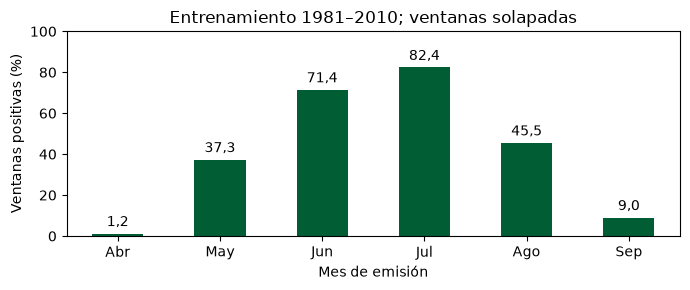

In [10]:
pretest_daily = daily.loc[:"2015-12-31"].copy()
frame = make_examples(pretest_daily, -3, 1981, 2015)
train = frame.loc[frame.valido & frame.year.le(2010)].copy()
val = frame.loc[frame.valido & frame.year.ge(2011)].copy()
assert train.objetivo_fin.max() < val.index.min()

display(
    pd.DataFrame(
        [
            {
                "conjunto": nombre,
                "n": len(g),
                "positivos": int(g.y.sum()),
                "proporción": g.y.mean(),
                "inicio": str(g.index.min().date()),
                "fin": str(g.index.max().date()),
            }
            for nombre, g in [("Entrenamiento", train), ("Validación", val)]
        ]
    )
)
display(train[FEATURES + ["y", "objetivo_inicio", "objetivo_fin"]].head(6))

frecuencia_mes = train.groupby("month").y.agg(
    n="size", positivos="sum", frecuencia="mean"
)
display(frecuencia_mes)
ax = (100 * frecuencia_mes.frecuencia).plot.bar(color="#015D34", rot=0, figsize=(7, 3))
ax.set(
    xlabel="Mes de emisión",
    ylabel="Ventanas positivas (%)",
    title="Entrenamiento 1981–2010; ventanas solapadas",
)
meses = {4: "Abr", 5: "May", 6: "Jun", 7: "Jul", 8: "Ago", 9: "Sep"}
ax.set_xticklabels([meses[mes] for mes in frecuencia_mes.index], rotation=0)
ax.set_ylim(0, 100)
ax.bar_label(
    ax.containers[0],
    labels=[f"{100 * valor:.1f}".replace(".", ",") for valor in frecuencia_mes.frecuencia],
    padding=3,
)
plt.tight_layout()
plt.savefig(OUT / "frecuencia_ventanas_entrenamiento.png", dpi=160)
plt.show()


## 4. Modelos y selección

La regresión logística y KNN usan `StandardScaler` dentro del pipeline de entrenamiento. Se comparan con el árbol, la mezcla de probabilidades, la frecuencia mensual y la persistencia.

El Brier medio de tres pliegues cronológicos determina los hiperparámetros. En 2011–2015 se elige el peso de la mezcla por Brier, y los umbrales y el modelo principal por F₀,₅. Este criterio da más peso a la precisión de los avisos.

In [11]:
def model_factory(name, cfg):
    if name == "logistica":
        # L2 es el valor por defecto con lbfgs; explicitado si la API lo permite.
        return make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=cfg["C"], solver="lbfgs", max_iter=10000, random_state=SEED
            ),
        )
    if name == "arbol":
        return DecisionTreeClassifier(criterion="gini", random_state=SEED, **cfg)
    return make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            weights="uniform", metric="euclidean", algorithm="brute", n_jobs=1, **cfg
        ),
    )


In [12]:
def score(y, p, pred, beta=0.5):
    y, p, pred = (
        np.asarray(y, dtype=int),
        np.asarray(p, dtype=float),
        np.asarray(pred, dtype=bool),
    )
    n = len(y)
    tp = int(((y == 1) & pred).sum())
    fp = int(((y == 0) & pred).sum())
    fn = int(((y == 1) & ~pred).sum())
    tn = int(((y == 0) & ~pred).sum())
    positive = tp + fn
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / positive if positive else np.nan

    def f(b):
        return (
            (1 + b * b) * tp / ((1 + b * b) * tp + fp + b * b * fn)
            if positive
            else np.nan
        )

    return {
        "n": n,
        "positivos": positive,
        "prevalencia": positive / n if n else np.nan,
        "avisos": tp + fp,
        "VP": tp,
        "FP": fp,
        "FN": fn,
        "VN": tn,
        "precision": precision,
        "recall": recall,
        "F0.5": f(0.5),
        "F1": f(1.0),
        "Fbeta": f(beta),
        "Brier": float(np.mean((p - y) ** 2)) if n else np.nan,
        "average_precision": (
            float(average_precision_score(y, p)) if positive else np.nan
        ),
    }


def choose_threshold(y, probs, beta):
    """Empates numericos <=1e-12 favorecen tau mayor; aviso p>=tau."""
    candidates = np.r_[np.unique(probs), np.nextafter(float(np.max(probs)), np.inf)]
    rows = []
    for tau in candidates:
        s = score(y, probs, probs >= tau, beta)
        rows.append(
            {
                "tau": float(tau),
                "Fbeta": s["Fbeta"],
                "precision": s["precision"],
                "recall": s["recall"],
                "VP": s["VP"],
                "FP": s["FP"],
                "FN": s["FN"],
            }
        )
    table = pd.DataFrame(rows)
    if not np.isfinite(table.Fbeta).any():
        raise ValueError("No hay positivos en validacion; no puede ajustarse Fbeta")
    best = table.Fbeta.max()
    selected = table.loc[np.isclose(table.Fbeta, best, atol=1e-12, rtol=0)].tau.max()
    return float(selected), table


def select_principal(metrics):
    best_f = max(metrics[m]["Fbeta"] for m in CLASSIFIERS)
    tied = [
        m
        for m in CLASSIFIERS
        if np.isclose(metrics[m]["Fbeta"], best_f, atol=1e-12, rtol=0)
    ]
    best_b = min(metrics[m]["Brier"] for m in tied)
    return next(
        m for m in tied if np.isclose(metrics[m]["Brier"], best_b, atol=1e-12, rtol=0)
    )


In [13]:
def select_config(name, frame, thermal):
    rows, candidate_rows = [], []
    for cfg_idx, cfg in enumerate(GRIDS[name]):
        bs = []
        for fold, (train_start, train_end, eval_start, eval_end) in enumerate(FOLDS, 1):
            tr = frame.loc[frame.valido & frame.year.between(train_start, train_end)]
            va = frame.loc[frame.valido & frame.year.between(eval_start, eval_end)]
            assert tr.objetivo_fin.max() < va.index.min()
            model = model_factory(name, cfg)
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                model.fit(tr[FEATURES], tr.y.astype(int))
            if name != "arbol":
                assert np.allclose(
                    model[0].mean_, tr[FEATURES].mean().to_numpy(), atol=1e-10
                )
            p = model.predict_proba(va[FEATURES])[:, 1]
            brier = float(np.mean((p - va.y.to_numpy()) ** 2))
            bs.append(brier)
            rows.append(
                {
                    "thermal": thermal,
                    "model": name,
                    "candidate": cfg_idx,
                    "params": json.dumps(cfg, sort_keys=True),
                    "fold": fold,
                    "train_start": train_start,
                    "train_end": train_end,
                    "eval_start": eval_start,
                    "eval_end": eval_end,
                    "n_train": len(tr),
                    "n_eval": len(va),
                    "Brier": brier,
                }
            )
        candidate_rows.append(
            {
                "thermal": thermal,
                "model": name,
                "candidate": cfg_idx,
                "params": json.dumps(cfg, sort_keys=True),
                "Brier_mean": float(np.mean(bs)),
                "Brier_std_population": float(np.std(bs)),
            }
        )
    best_score = min(r["Brier_mean"] for r in candidate_rows)
    tied = [
        r
        for r in candidate_rows
        if np.isclose(r["Brier_mean"], best_score, atol=1e-12, rtol=0)
    ]
    # Orden de la rejilla: menor C, menor profundidad/mayor hoja, mayor k.
    winner = min(tied, key=lambda r: r["candidate"])
    for r in candidate_rows:
        r["selected"] = r["candidate"] == winner["candidate"]
    return GRIDS[name][winner["candidate"]], rows, candidate_rows


In [14]:
def episodes(daily, thermal, first_year, last_year):
    """Rachas maximales dentro de abril-septiembre; episodios son >=3 dias.

    Un episodio de L dias contiene L-2 subventanas completas, pero las
    emisiones cubren objetivos desde 2/abril: documentar esta frontera.
    """
    rows = []
    for year in range(first_year, last_year + 1):
        d = daily.loc[f"{year}-04-01":f"{year}-09-30"]
        cold = (d.valido_dia & (d.tmin <= thermal)).to_numpy()
        starts = np.flatnonzero(cold & ~np.r_[False, cold[:-1]])
        ends = np.flatnonzero(cold & ~np.r_[cold[1:], False])
        for start, end in zip(starts, ends):
            length = int(end - start + 1)
            if length >= 3:
                rows.append(
                    {
                        "thermal": thermal,
                        "year": year,
                        "inicio": str(d.index[start].date()),
                        "fin": str(d.index[end].date()),
                        "dias": length,
                        "tmin_min": float(d.tmin.iloc[start : end + 1].min()),
                        "subventanas_tres_dias": length - 2,
                        "toca_borde_temporada": bool(start == 0 or end == len(d) - 1),
                    }
                )
    return pd.DataFrame(
        rows,
        columns=[
            "thermal",
            "year",
            "inicio",
            "fin",
            "dias",
            "tmin_min",
            "subventanas_tres_dias",
            "toca_borde_temporada",
        ],
    )


def sanity_tests(daily):
    # Modificar el futuro no puede cambiar atributos del presente.
    ref = make_examples(daily.loc[:"2015-12-31"], -3, 1981, 2015)
    d = pd.Timestamp("2010-06-15")
    changed = daily.loc[:"2015-12-31"].copy()
    changed.loc[d + pd.Timedelta(days=1) :, ["tmin", "tmax"]] += 100
    new = make_examples(changed, -3, 1981, 2015)
    assert np.array_equal(
        ref.loc[d, FEATURES].to_numpy(), new.loc[d, FEATURES].to_numpy()
    )
    assert ref.loc[d, "objetivo_fin"] == d + pd.Timedelta(days=3)
    assert list(ref.loc[d, [f"tmin_lag_{i}" for i in range(6, -1, -1)]]) == list(
        daily.loc[d - pd.Timedelta(days=6) : d, "tmin"]
    )
    assert all(
        make_examples(daily, -3, y, y).shape[0] == 180 for y in [1981, 1984, 2016, 2020]
    )
    s = score([1, 1, 0], [0.8, 0.2, 0.7], [1, 0, 1])
    assert np.isclose(s["F0.5"], 1.25 / (1.25 + 1 + 0.25))
    z = score([0, 0], [0.1, 0.2], [0, 0])
    assert z["precision"] == 0 and np.isnan(z["recall"]) and np.isnan(z["F0.5"])
    # QC: un dia invalido invalida t-6..t+3, sin rellenar el objetivo.
    bad = daily.copy()
    bad.loc[d, "valido_dia"] = False
    check = make_examples(bad, -3, 2010, 2010)
    assert not check.loc[
        d - pd.Timedelta(days=3) : d + pd.Timedelta(days=6), "valido"
    ].any()
    assert (
        check.loc[d - pd.Timedelta(days=4), "valido"]
        == make_examples(daily, -3, 2010, 2010).loc[d - pd.Timedelta(days=4), "valido"]
    )
    return {
        "future_perturbation_does_not_change_features": True,
        "exact_feature_alignment": True,
        "three_future_days": True,
        "180_candidate_dates_per_year": True,
        "Fbeta_formula": True,
        "no_positives_convention": True,
        "invalid_full_window_no_imputation": True,
        "temporal_folds_no_overlap_and_train_scalers_checked_during_fit": True,
    }


In [15]:
def auditar_escaladores(state, daily, out):
    """Comprueba las medias y escalas de los modelos finales contra 1981–2010."""
    rows = []
    for key, st in state.items():
        frame = make_examples(daily.loc[:"2015-12-31"], float(key), 1981, 2015)
        train = frame.loc[frame.valido & frame.year.le(2010), FEATURES]
        for name in ["logistica", "knn"]:
            scaler = st["models"][name][0]
            assert int(scaler.n_samples_seen_) == len(train)
            assert np.allclose(scaler.mean_, train.mean().to_numpy(), atol=1e-10)
            assert np.allclose(scaler.var_, train.var(ddof=0).to_numpy(), atol=1e-10)
            z = scaler.transform(train)
            assert np.allclose(z.mean(axis=0), 0, atol=1e-10)
            for j, feature in enumerate(FEATURES):
                rows.append(
                    {
                        "thermal": float(key),
                        "model": name,
                        "feature": feature,
                        "n_fit": len(train),
                        "training_mean": scaler.mean_[j],
                        "training_scale": scaler.scale_[j],
                        "transformed_training_mean": z[:, j].mean(),
                        "transformed_training_std": z[:, j].std(),
                        "periodo_fit": "1981-2010",
                        "usa_validacion_o_prueba_en_fit": False,
                    }
                )
    save_csv(pd.DataFrame(rows), out / "auditoria_escalado.csv")


In [16]:
def prepare(daily, manifest, out):
    begin = time.perf_counter()
    out.mkdir(parents=True, exist_ok=True)
    describir_preprocesamiento(daily, out)
    tests = sanity_tests(daily)
    write_json(out / "sanity_tests.json", tests)
    # No ejemplos, etiquetas ni probabilidades de prueba durante seleccion.
    pretest_daily = daily.loc[:"2015-12-31"].copy()
    (
        all_cv,
        all_means,
        all_val,
        all_alpha,
        all_thresholds,
        all_pop,
        all_month,
        all_eps,
    ) = ([], [], [], [], [], [], [], [])
    state, decisions = {}, {}
    for thermal in THERMALS:
        print(f"Ajuste y validación para {thermal:g} °C", flush=True)
        frame = make_examples(pretest_daily, thermal, 1981, 2015)
        train = frame.loc[frame.valido & frame.year.le(2010)]
        val = frame.loc[frame.valido & frame.year.ge(2011)]
        configs, fitted = {}, {}
        for name in GRIDS:
            cfg, cvrows, means = select_config(name, frame, thermal)
            configs[name] = cfg
            all_cv.extend(cvrows)
            all_means.extend(means)
            fitted[name] = model_factory(name, cfg)
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                fitted[name].fit(train[FEATURES], train.y.astype(int))
        probs = {n: fitted[n].predict_proba(val[FEATURES])[:, 1] for n in fitted}
        monthly = train.groupby("month").y.mean().to_dict()
        probs["frecuencia_mensual"] = val.month.map(monthly).to_numpy()
        probs["persistencia"] = val.persistencia.to_numpy()
        arows = []
        for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:
            p = alpha * probs["logistica"] + (1 - alpha) * probs["arbol"]
            arows.append(
                {
                    "thermal": thermal,
                    "alpha": alpha,
                    "Brier": float(np.mean((p - val.y.to_numpy()) ** 2)),
                }
            )
        low = min(r["Brier"] for r in arows)
        alpha = max(
            r["alpha"] for r in arows if np.isclose(r["Brier"], low, atol=1e-12, rtol=0)
        )
        for r in arows:
            r["selected"] = r["alpha"] == alpha
        all_alpha.extend(arows)
        probs["mezcla"] = alpha * probs["logistica"] + (1 - alpha) * probs["arbol"]
        if alpha in [0.0, 1.0]:
            assert np.array_equal(
                probs["mezcla"], probs["logistica" if alpha == 1 else "arbol"]
            )
        decisions_by_beta = {}
        for beta in [0.5, 1.0]:
            thresholds, metrics = {}, {}
            for name in MODELS:
                if name == "persistencia":
                    tau = 0.5
                else:
                    tau, table = choose_threshold(val.y.to_numpy(), probs[name], beta)
                    table["thermal"], table["beta"], table["model"] = (
                        thermal,
                        beta,
                        name,
                    )
                    all_thresholds.extend(table.to_dict("records"))
                thresholds[name] = tau
                metrics[name] = score(val.y, probs[name], probs[name] >= tau, beta)
                all_val.append(
                    {
                        "thermal": thermal,
                        "beta": beta,
                        "model": name,
                        "tau": tau,
                        **metrics[name],
                    }
                )
            principal = select_principal(metrics)
            decisions_by_beta[str(beta)] = {
                "thresholds": thresholds,
                "principal": principal,
                "validation_metrics": metrics,
            }
        key = str(int(thermal))
        decisions[key] = {
            "thermal": thermal,
            "selected_configs": configs,
            "alpha": alpha,
            "monthly_training_frequencies": monthly,
            "decisions_by_beta": decisions_by_beta,
            "training_n": len(train),
            "validation_n": len(val),
        }
        state[key] = {
            "models": fitted,
            "monthly": monthly,
            "validation_dates": val.index,
            "validation_probs": probs,
        }
        pred_val = val[["y", "persistencia", "objetivo_inicio", "objetivo_fin"]].copy()
        for n in MODELS:
            pred_val[f"p_{n}"] = probs[n]
        save_csv(
            pred_val.reset_index(),
            out / f"predicciones_validacion_m{abs(int(thermal))}.csv",
        )
        for label, a, b in [("entrenamiento", 1981, 2010), ("validacion", 2011, 2015)]:
            sub = frame.loc[frame.year.between(a, b)]
            all_pop.append(
                {
                    "thermal": thermal,
                    "split": label,
                    "candidate_n": len(sub),
                    "valid_n": int(sub.valido.sum()),
                    "invalid_n": int((~sub.valido).sum()),
                    "positive_n": int(sub.y.sum()),
                    "prevalence": float(sub.y.mean()),
                }
            )
        for month, g in train.groupby("month"):
            all_month.append(
                {
                    "thermal": thermal,
                    "month": month,
                    "n": len(g),
                    "positive_n": int(g.y.sum()),
                    "window_frequency": float(g.y.mean()),
                    "tmin_mean": float(g.tmin_lag_0.mean()),
                    "tmin_min": float(g.tmin_lag_0.min()),
                    "tmax_mean": float(g.tmax_lag_0.mean()),
                }
            )
        all_eps.append(episodes(pretest_daily, thermal, 1981, 2015))
        print(
            f"  configs={configs}; alpha={alpha}; principal={decisions_by_beta['0.5']['principal']}",
            flush=True,
        )
    write_json(
        out / "freeze.json",
        {
            "protocol_version": "1.0",
            "seed": SEED,
            "feature_order": FEATURES,
            "thermal_definitions": THERMALS,
            "train": "1981-2010",
            "validation": "2011-2015",
            "test": "2016-2020 (NO EVALUADO EN ESTA FASE)",
            "model_fit_uses_validation": False,
            "season_emission": "04-01..09-27 inclusive; 180/y",
            "target": "all three tmin(t+1:t+3) <= thermal",
            "seasonal_encoding": "sin/cos(2*pi*dayofyear/D), D=365 or 366 of emission year",
            "alpha_formula": "alpha*LR+(1-alpha)*tree",
            "alpha_tie": "higher alpha",
            "tie_tolerance_absolute": 1e-12,
            "threshold_rule": "p>=tau; candidates unique validation probabilities + nextafter(max,+inf); Fbeta tie higher tau",
            "config_tie": "lower C; lower depth then larger leaf; larger k",
            "principal_tie": "higher validation Fbeta, then lower Brier, then LR/tree/KNN/mix",
            "beta1_scope": "secondary; same configurations, fitted models, probabilities and alpha as beta0.5",
            "bootstrap": "1000 paired calendar moving-block samples; six blocks of30 per season within each of five fixed test years; shared mask and indices; seed2026",
            "sources": manifest,
            "code_sha256": huella_codigo(),
            "code_hash_scope": "Funciones ejecutadas y parámetros predefinidos; codigo_ejecutado.py",
            "versions": {
                "python": platform.python_version(),
                "numpy": np.__version__,
                "pandas": pd.__version__,
                "sklearn": sklearn.__version__,
            },
            "decisions": decisions,
        },
    )
    auditar_escaladores(state, daily, out)
    (out / "codigo_ejecutado.py").write_text(
        codigo_fuente_ejecutado(), encoding="utf-8"
    )
    for name, rows in [
        ("cv_folds", all_cv),
        ("cv_resumen", all_means),
        ("metricas_validacion", all_val),
        ("alpha_validacion", all_alpha),
        ("busqueda_umbrales_validacion", all_thresholds),
        ("prevalencia_pretest", all_pop),
        ("eda_mensual_entrenamiento", all_month),
    ]:
        save_csv(pd.DataFrame(rows), out / f"{name}.csv")
    save_csv(pd.concat(all_eps, ignore_index=True), out / "episodios_pretest.csv")
    write_json(out / "timing_prepare.json", {"seconds": time.perf_counter() - begin})
    return state


## 5. Evaluación temporal

La prueba aplica los modelos y umbrales fijados en validación. El remuestreo usa 1 000 réplicas pareadas con bloques de 30 días dentro de cada temporada. Los intervalos describen la variación de las diferencias entre métodos en las cinco temporadas observadas.

In [17]:
def bootstrap_test(frame, probs, decision, thermal, beta, n_boot=1000):
    """Remuestreo por calendario antes de la mascara, pareado entre metodos."""
    rng = np.random.default_rng(SEED)
    years = sorted(frame.year.unique())
    assert len(years) == 5 and len(frame) == 900
    y = frame.y.to_numpy()
    valid = frame.valido.to_numpy()
    allp = {n: np.asarray(probs[n], float) for n in MODELS}
    thresholds = decision["thresholds"]
    principal = decision["principal"]
    rows, deltas = [], []
    draws = np.empty((n_boot, 5, 6), dtype=np.int16)
    # Inicios0..150 inclusive: ningun bloque cruza septiembre o cambia de ano.
    for rep in range(n_boot):
        picks = []
        for j, yr in enumerate(years):
            locations = np.flatnonzero(frame.year.to_numpy() == yr)
            assert len(locations) == 180
            starts = rng.integers(0, 151, size=6)
            draws[rep, j] = starts
            picks.extend(locations[(starts[:, None] + np.arange(30)).ravel()].tolist())
        idx = np.asarray(picks, dtype=int)
        idx = idx[valid[idx]]
        scores = {}
        for name in MODELS:
            p = allp[name][idx]
            scores[name] = score(y[idx], p, p >= thresholds[name], beta)
            rows.append(
                {
                    "replica": rep,
                    "thermal": thermal,
                    "beta": beta,
                    "model": name,
                    **{
                        k: scores[name][k]
                        for k in [
                            "n",
                            "positivos",
                            "precision",
                            "recall",
                            "F0.5",
                            "F1",
                            "Fbeta",
                            "Brier",
                        ]
                    },
                }
            )
        for comparator in MODELS:
            if comparator == principal:
                continue
            deltas.append(
                {
                    "replica": rep,
                    "thermal": thermal,
                    "beta": beta,
                    "principal": principal,
                    "comparador": comparator,
                    "delta_F0.5": scores[principal]["F0.5"]
                    - scores[comparator]["F0.5"],
                    "delta_F1": scores[principal]["F1"] - scores[comparator]["F1"],
                    "delta_Brier": scores[principal]["Brier"]
                    - scores[comparator]["Brier"],
                }
            )
        for comparator in ["logistica", "arbol"]:
            deltas.append(
                {
                    "replica": rep,
                    "thermal": thermal,
                    "beta": beta,
                    "principal": "mezcla",
                    "comparador": comparator,
                    "delta_F0.5": scores["mezcla"]["F0.5"] - scores[comparator]["F0.5"],
                    "delta_F1": scores["mezcla"]["F1"] - scores[comparator]["F1"],
                    "delta_Brier": scores["mezcla"]["Brier"]
                    - scores[comparator]["Brier"],
                }
            )
    return (
        pd.DataFrame(rows),
        pd.DataFrame(deltas).drop_duplicates(
            ["replica", "thermal", "beta", "principal", "comparador"]
        ),
        draws,
    )


def intervals(table, groupcols, values):
    rows = []
    for key, g in table.groupby(groupcols, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        for value in values:
            arr = g[value].to_numpy()
            valid = arr[np.isfinite(arr)]
            rows.append(
                {
                    **dict(zip(groupcols, key)),
                    "metric": value,
                    "lower_2.5": (
                        float(np.percentile(valid, 2.5)) if len(valid) else np.nan
                    ),
                    "upper_97.5": (
                        float(np.percentile(valid, 97.5)) if len(valid) else np.nan
                    ),
                    "replicas_estimables": len(valid),
                    "replicas_totales": len(g),
                    "fraction_not_estimable": 1 - len(valid) / len(g),
                }
            )
    return pd.DataFrame(rows)


In [18]:
def resumir(out):
    out = Path(out)
    avisos = pd.read_csv(out / "predicciones_prueba_m3.csv")
    episodios = pd.read_csv(out / "episodios_prueba.csv")
    episodios = episodios.loc[episodios.thermal == -3]
    validos = avisos["valido"].astype(bool)
    a = avisos.loc[validos, "aviso_beta0.5_logistica"]
    b = avisos.loc[validos, "aviso_beta0.5_arbol"]
    resultado = {
        "alcance": "Descripcion posterior de salidas, sin nuevas decisiones de ajuste",
        "thermal": -3,
        "beta": 0.5,
        "n": int(validos.sum()),
        "desacuerdo_avisos_logistica_arbol": int((a != b).sum()),
        "fraccion_desacuerdo": float((a != b).mean()),
        "episodios_prueba": len(episodios),
        "episodios_por_ano": {
            str(int(k)): int(v) for k, v in episodios.groupby("year").size().items()
        },
        "subventanas_en_episodios": int(episodios.subventanas_tres_dias.sum()),
        "positivos_prueba": int(avisos.loc[validos, "y"].sum()),
        "episodios_tocan_borde": int(episodios.toca_borde_temporada.sum()),
    }
    (out / "resumen_descriptivo.json").write_text(
        json.dumps(resultado, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    return resultado


In [19]:
def test(daily, state, out):
    begin = time.perf_counter()
    frozen = json.loads((out / "freeze.json").read_text(encoding="utf-8"))
    assert (
        frozen["code_sha256"] == huella_codigo()
    ), "El codigo cambio despues de congelar decisiones"
    allmetrics, allannual, allpop, eps = [], [], [], []
    boot_tables, delta_tables = [], []
    for thermal in THERMALS:
        print(f"Prueba para {thermal:g} °C", flush=True)
        key = str(int(thermal))
        f = frozen["decisions"][key]
        st = state[key]
        frame = make_examples(daily, thermal, 2016, 2020)
        valid = frame.valido.to_numpy()
        sub = frame.loc[frame.valido]
        probs = {}
        for n, m in st["models"].items():
            probs[n] = np.full(len(frame), np.nan)
            probs[n][valid] = m.predict_proba(sub[FEATURES])[:, 1]
        probs["frecuencia_mensual"] = frame.month.map(st["monthly"]).to_numpy(
            dtype=float
        )
        probs["persistencia"] = frame.persistencia.to_numpy()
        probs["mezcla"] = (
            f["alpha"] * probs["logistica"] + (1 - f["alpha"]) * probs["arbol"]
        )
        if f["alpha"] in [0.0, 1.0]:
            assert np.array_equal(
                probs["mezcla"][valid],
                probs["logistica" if f["alpha"] == 1 else "arbol"][valid],
            )
        predictions = frame[
            [
                "objetivo_inicio",
                "objetivo_fin",
                "year",
                "month",
                "valido_historia",
                "valido_objetivo",
                "valido",
                "y",
            ]
        ].copy()
        for name in MODELS:
            predictions[f"p_{name}"] = probs[name]
        for beta in [0.5, 1.0]:
            dec = f["decisions_by_beta"][str(beta)]
            for name in MODELS:
                tau = dec["thresholds"][name]
                prediction = probs[name] >= tau
                predictions[f"aviso_beta{beta}_{name}"] = pd.Series(
                    prediction.astype(float), index=frame.index
                ).where(frame.valido)
                allmetrics.append(
                    {
                        "thermal": thermal,
                        "beta": beta,
                        "model": name,
                        "principal": name == dec["principal"],
                        "tau": tau,
                        **score(
                            frame.y[valid], probs[name][valid], prediction[valid], beta
                        ),
                    }
                )
                for year in range(2016, 2021):
                    mask = valid & (frame.year.to_numpy() == year)
                    allannual.append(
                        {
                            "thermal": thermal,
                            "beta": beta,
                            "model": name,
                            "year": year,
                            "principal": name == dec["principal"],
                            **score(
                                frame.y[mask], probs[name][mask], prediction[mask], beta
                            ),
                        }
                    )
            b, d, draws = bootstrap_test(frame, probs, dec, thermal, beta)
            boot_tables.append(b)
            delta_tables.append(d)
            if thermal == -3 and beta == 0.5:
                np.save(out / "bootstrap_inicios_calendario.npy", draws)
        save_csv(
            predictions.reset_index(),
            out / f"predicciones_prueba_m{abs(int(thermal))}.csv",
        )
        allpop.append(
            {
                "thermal": thermal,
                "split": "prueba",
                "candidate_n": len(frame),
                "valid_n": int(valid.sum()),
                "invalid_n": int((~valid).sum()),
                "positive_n": int(frame.y.sum()),
                "prevalence": float(frame.y.mean()),
            }
        )
        eps.append(episodes(daily, thermal, 2016, 2020))
    metrics = pd.DataFrame(allmetrics)
    annual = pd.DataFrame(allannual)
    boot = pd.concat(boot_tables, ignore_index=True)
    deltas = pd.concat(delta_tables, ignore_index=True)
    save_csv(metrics, out / "metricas_prueba.csv")
    save_csv(annual, out / "metricas_prueba_anuales.csv")
    save_csv(pd.DataFrame(allpop), out / "prevalencia_prueba.csv")
    save_csv(pd.concat(eps, ignore_index=True), out / "episodios_prueba.csv")
    save_csv(boot, out / "bootstrap_metricas_1000.csv")
    save_csv(deltas, out / "bootstrap_diferencias_1000.csv")
    save_csv(
        intervals(
            boot,
            ["thermal", "beta", "model"],
            ["precision", "recall", "F0.5", "F1", "Brier"],
        ),
        out / "bootstrap_intervalos_metricas.csv",
    )
    save_csv(
        intervals(
            deltas,
            ["thermal", "beta", "principal", "comparador"],
            ["delta_F0.5", "delta_F1", "delta_Brier"],
        ),
        out / "bootstrap_intervalos_diferencias.csv",
    )
    # Hipotesis fijadas: comparar puntos estrictamente, sin llamarlos significativos.
    conclusions = {}
    for thermal in THERMALS:
        key = str(int(thermal))
        sel = frozen["decisions"][key]["decisions_by_beta"]["0.5"]["principal"]
        g = metrics.loc[(metrics.thermal == thermal) & (metrics.beta == 0.5)].set_index(
            "model"
        )
        diffs = {
            ref: float(g.loc[sel, "F0.5"] - g.loc[ref, "F0.5"])
            for ref in ["persistencia", "frecuencia_mensual"]
        }
        md = {
            ref: float(g.loc["mezcla", "Brier"] - g.loc[ref, "Brier"])
            for ref in ["logistica", "arbol"]
        }
        conclusions[key] = {
            "principal": sel,
            "alpha": frozen["decisions"][key]["alpha"],
            "delta_F0.5_vs_referencias": diffs,
            "hipotesis_principal_apoyada_puntualmente": all(
                v > 0 for v in diffs.values()
            ),
            "delta_Brier_mezcla_vs_componentes": md,
            "hipotesis_complementaria_apoyada_puntualmente": all(
                v < 0 for v in md.values()
            ),
            "scope": "Puntos historicos; intervalos bootstrap exploratorios, no prueba de significancia ni validacion productiva.",
        }
    write_json(out / "conclusiones_numericas.json", conclusions)
    write_json(
        out / "timing_test.json",
        {
            "seconds": time.perf_counter() - begin,
            "freeze_sha256": sha(out / "freeze.json"),
            "bootstrap_replicates": 1000,
        },
    )
    resumir(out)


## 6. Ajuste y validación

`freeze.json` registra las decisiones de validación antes de evaluar 2016–2020. La auditoría de escalado compara los parámetros aprendidos con las estadísticas de entrenamiento.

In [20]:
modelos_ajustados = prepare(daily, manifest, OUT)
frozen = json.loads((OUT / "freeze.json").read_text(encoding="utf-8"))
ajuste_principal = frozen["decisions"]["-3"]
principal = ajuste_principal["decisions_by_beta"]["0.5"]["principal"]

print(f"Modelo principal en validación para −3 °C: {principal}")
print("Configuraciones", ajuste_principal["selected_configs"])
print(f"Peso de logística en la mezcla: {ajuste_principal['alpha']:.2f}")
display(pd.read_csv(OUT / "metricas_validacion.csv").query("thermal == -3 and beta == 0.5")[[
    "model", "tau", "precision", "recall", "F0.5", "Brier"
]].round(4))


Ajuste y validación para -3 °C


  configs={'logistica': {'C': 0.1}, 'arbol': {'max_depth': 3, 'min_samples_leaf': 30}, 'knn': {'n_neighbors': 31}}; alpha=0.75; principal=logistica


Ajuste y validación para -2 °C


  configs={'logistica': {'C': 0.1}, 'arbol': {'max_depth': 3, 'min_samples_leaf': 30}, 'knn': {'n_neighbors': 31}}; alpha=0.75; principal=mezcla


Ajuste y validación para -4 °C


  configs={'logistica': {'C': 0.1}, 'arbol': {'max_depth': 3, 'min_samples_leaf': 10}, 'knn': {'n_neighbors': 31}}; alpha=0.75; principal=logistica


Modelo principal en validación para −3 °C: logistica
Configuraciones {'arbol': {'max_depth': 3, 'min_samples_leaf': 30}, 'knn': {'n_neighbors': 31}, 'logistica': {'C': 0.1}}
Peso de logística en la mezcla: 0.75


,model,tau,precision,recall,F0.5,Brier
0,logistica,0.5520,0.7341,0.7910,0.7448,0.1359
1,arbol,0.7395,0.7398,0.7045,0.7325,0.1438
2,knn,0.6129,0.7233,0.6866,0.7156,0.1478
3,mezcla,0.5268,0.7288,0.7940,0.7409,0.1359
4,frecuencia_mensual,0.7144,0.6885,0.6269,0.6752,0.1651
5,persistencia,0.5000,0.6627,0.6627,0.6627,0.2511


### Ajuste por pliegues y escalado

In [21]:
cv = pd.read_csv(OUT / "cv_resumen.csv").query("thermal == -3")
display(cv[["model", "params", "Brier_mean", "selected"]].round(6))

escalado = pd.read_csv(OUT / "auditoria_escalado.csv").query("thermal == -3")
display(escalado.groupby("model", as_index=False).agg(
    atributos=("feature", "size"),
    emisiones_fit=("n_fit", "min"),
    periodo_fit=("periodo_fit", "first"),
    usa_validacion_o_prueba=("usa_validacion_o_prueba_en_fit", "any"),
))


,model,params,Brier_mean,selected
0,logistica,"{""C"": 0.1}",0.126004,True
1,logistica,"{""C"": 1.0}",0.126050,False
2,logistica,"{""C"": 10.0}",0.126075,False
3,arbol,"{""max_depth"": 3, ""min_samples_leaf"": 30}",0.132559,True
4,arbol,"{""max_depth"": 3, ""min_samples_leaf"": 10}",0.132559,False
5,arbol,"{""max_depth"": 5, ""min_samples_leaf"": 30}",0.137471,False
6,arbol,"{""max_depth"": 5, ""min_samples_leaf"": 10}",0.139037,False
7,arbol,"{""max_depth"": 8, ""min_samples_leaf"": 30}",0.145376,False
8,arbol,"{""max_depth"": 8, ""min_samples_leaf"": 10}",0.160180,False
9,knn,"{""n_neighbors"": 31}",0.138362,True


,model,atributos,emisiones_fit,periodo_fit,usa_validacion_o_prueba
0,knn,16,5400,1981-2010,False
1,logistica,16,5400,1981-2010,False


## 7. Resultados de prueba

La comparación principal usa −3 °C y F₀,₅. Se muestran las métricas y los conteos de la prueba reservada.

In [22]:
test(daily, modelos_ajustados, OUT)
metricas = pd.read_csv(OUT / "metricas_prueba.csv")
principal_test = metricas.query("thermal == -3 and beta == 0.5").copy()
display(
    principal_test[
        [
            "model",
            "principal",
            "tau",
            "n",
            "positivos",
            "VP",
            "FP",
            "FN",
            "VN",
            "precision",
            "recall",
            "F0.5",
            "F1",
            "Brier",
        ]
    ]
)


Prueba para -3 °C


Prueba para -2 °C


Prueba para -4 °C


,model,principal,tau,n,positivos,VP,FP,FN,VN,precision,recall,F0.5,F1,Brier
0,logistica,True,0.551970,900,330,272,75,58,495,0.783862,0.824242,0.791618,0.803545,0.112431
1,arbol,False,0.739496,900,330,241,62,89,508,0.795380,0.730303,0.781453,0.761453,0.122625
2,knn,False,0.612903,900,330,239,70,91,500,0.773463,0.724242,0.763091,0.748044,0.123214
3,mezcla,False,0.526763,900,330,271,79,59,491,0.774286,0.821212,0.783237,0.797059,0.113003
4,frecuencia_mensual,False,0.714444,900,330,207,98,123,472,0.678689,0.627273,0.667742,0.651969,0.165874
5,persistencia,False,0.500000,900,330,236,94,94,476,0.715152,0.715152,0.715152,0.715152,0.208889


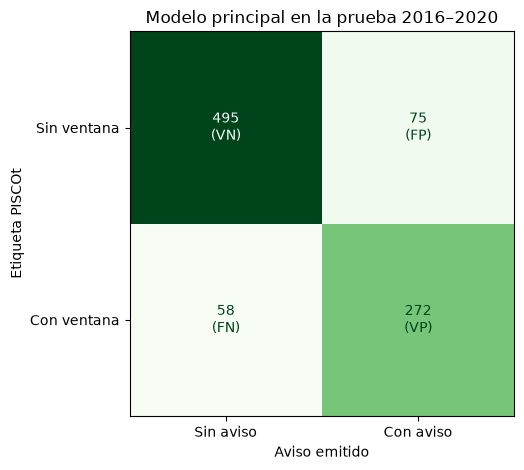

In [23]:
fila = principal_test.set_index("model").loc[principal]
matriz = np.array([[int(fila.VN), int(fila.FP)], [int(fila.FN), int(fila.VP)]])
grafica = ConfusionMatrixDisplay(matriz, display_labels=["Sin ventana", "Con ventana"]).plot(
    cmap="Greens", colorbar=False
)
grafica.ax_.set(xlabel="Aviso emitido", ylabel="Etiqueta PISCOt", title="Modelo principal en la prueba 2016–2020")
grafica.ax_.set_xticklabels(["Sin aviso", "Con aviso"])
for fila_texto, clases in zip(grafica.text_, [("VN", "FP"), ("FN", "VP")]):
    for etiqueta, clase in zip(fila_texto, clases):
        etiqueta.set_text(f"{etiqueta.get_text()}\n({clase})")
plt.tight_layout()
plt.savefig(OUT / "matriz_confusion_principal.png", dpi=160)
plt.show()


### Comparación de los seis métodos

El verde identifica el modelo elegido en validación.

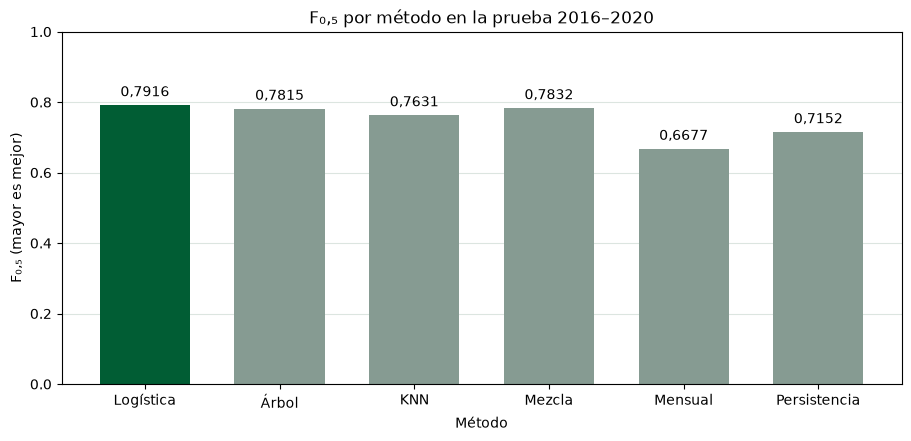

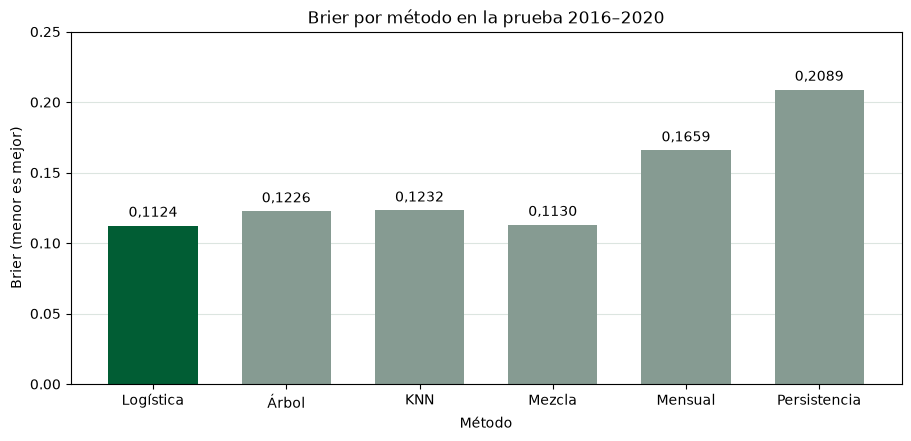

In [24]:
nombres_metodos = {
    "logistica": "Logística", "arbol": "Árbol", "knn": "KNN",
    "mezcla": "Mezcla", "frecuencia_mensual": "Mensual", "persistencia": "Persistencia",
}
metodos = principal_test["model"].map(nombres_metodos)
colores = np.where(principal_test["principal"], "#015D34", "#869B92")

for columna, titulo, eje, maximo, archivo in [
    ("F0.5", "F₀,₅ por método en la prueba 2016–2020", "F₀,₅ (mayor es mejor)", 1.0, "comparacion_f05.png"),
    ("Brier", "Brier por método en la prueba 2016–2020", "Brier (menor es mejor)", 0.25, "comparacion_brier.png"),
]:
    valores = principal_test[columna]
    fig, ax = plt.subplots(figsize=(9, 4.3), layout="constrained")
    barras = ax.bar(metodos, valores, color=colores, width=0.67)
    ax.set(title=titulo, xlabel="Método", ylabel=eje, ylim=(0, maximo))
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#DCE5E0", linewidth=0.8)
    ax.bar_label(barras, labels=[f"{v:.4f}".replace(".", ",") for v in valores], padding=4)
    fig.savefig(OUT / archivo, dpi=160)
    plt.show()


## 8. Variación anual y sensibilidad

El desglose anual conserva el modelo y el umbral de aviso. El análisis con −2 y −4 °C vuelve a aplicar el protocolo para cada definición térmica. La selección por F₁ conserva los modelos ajustados y cambia el criterio para elegir el umbral de aviso y el modelo principal.

In [25]:
anuales = pd.read_csv(OUT / "metricas_prueba_anuales.csv")
display(anuales.loc[
    anuales.thermal.eq(-3) & anuales.beta.eq(0.5) & anuales.model.eq(principal),
    ["year", "n", "positivos", "precision", "recall", "F0.5", "Brier"],
].round(4))

display(metricas.loc[
    metricas.beta.eq(0.5) & metricas.principal,
    ["thermal", "model", "positivos", "F0.5", "Brier"],
].sort_values("thermal", ascending=False).round(4))

intervalos = pd.read_csv(OUT / "bootstrap_intervalos_diferencias.csv")
principales = intervalos.query("thermal == -3 and beta == 0.5")
comparaciones = (
    principales.metric.eq("delta_F0.5") & principales.comparador.isin(["persistencia", "frecuencia_mensual"])
) | (
    principales.metric.eq("delta_Brier") & principales.principal.eq("mezcla")
)
display(principales.loc[
    comparaciones,
    ["metric", "principal", "comparador", "lower_2.5", "upper_97.5"],
].round(4))

display(metricas.loc[
    metricas.thermal.eq(-3) & metricas.beta.eq(1) & metricas.model.isin(["logistica", "mezcla"]),
    ["model", "principal", "tau", "FP", "FN", "F1"],
].round(6))


,year,n,positivos,precision,recall,F0.5,Brier
0,2016,180,72,0.7600,0.7917,0.7661,0.1375
1,2017,180,62,0.8750,0.9032,0.8805,0.0747
2,2018,180,65,0.7183,0.7846,0.7307,0.1408
3,2019,180,81,0.8101,0.7901,0.8060,0.1168
4,2020,180,50,0.7586,0.8800,0.7801,0.0924


,thermal,model,positivos,F0.5,Brier
15,-2,mezcla,422,0.8396,0.1202
0,-3,logistica,330,0.7916,0.1124
24,-4,logistica,255,0.6879,0.1175


,metric,principal,comparador,lower_2.5,upper_97.5
45,delta_F0.5,logistica,frecuencia_mensual,0.0636,0.2102
54,delta_F0.5,logistica,persistencia,0.0364,0.1117
59,delta_Brier,mezcla,arbol,-0.0151,-0.0052
62,delta_Brier,mezcla,logistica,-0.0011,0.0019


,model,principal,tau,FP,FN,F1
6,logistica,False,0.436735,109,35,0.803815
9,mezcla,True,0.388272,120,28,0.803191


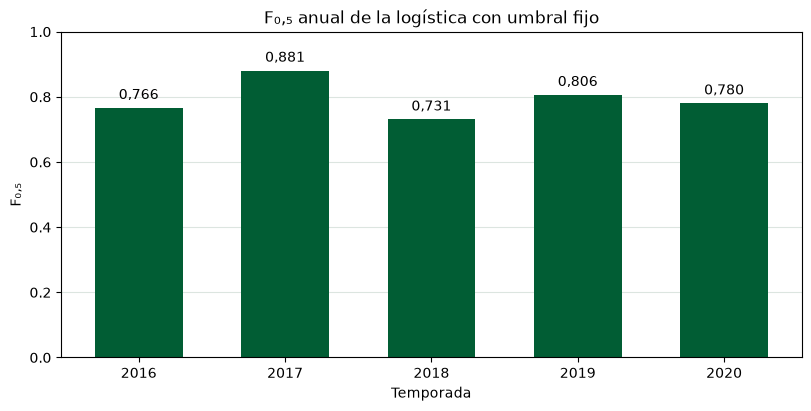

In [26]:
anual_principal = anuales.loc[
    anuales.thermal.eq(-3) & anuales.beta.eq(0.5) & anuales.model.eq(principal)
].sort_values("year")
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
barras = ax.bar(anual_principal["year"].astype(str), anual_principal["F0.5"], color="#015D34", width=0.6)
ax.set(title="F₀,₅ anual de la logística con umbral fijo", xlabel="Temporada", ylabel="F₀,₅", ylim=(0, 1))
ax.set_axisbelow(True)
ax.grid(axis="y", color="#DCE5E0", linewidth=0.8)
ax.bar_label(barras, labels=[f"{v:.3f}".replace(".", ",") for v in anual_principal["F0.5"]], padding=4)
fig.savefig(OUT / "desempeno_anual.png", dpi=160)
plt.show()


## 9. Interpretación y fuente

La logística obtuvo el mayor F₀,₅ en la prueba. El Brier de la mezcla fue menor que el del árbol y ligeramente mayor que el de la logística. El intervalo para la diferencia entre mezcla y logística incluye cero. La evaluación corresponde a la condición térmica de una celda reconstruida.

Las tablas, las decisiones de validación y las predicciones quedan en `resultados_grupo9/`.

[Huerta et al. (2023), PISCOt v1.2](https://doi.org/10.1038/s41597-023-02777-w) · [Serie diaria de 0,10°](https://doi.org/10.6084/m9.figshare.22712365.v3)